In [7]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Set plotting style
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.autolayout": True, "font.size": 11})

# 1. Create directories programmatically if they don't exist
os.makedirs("data/raw", exist_ok=True)
os.makedirs("data/processed", exist_ok=True)
os.makedirs("outputs/figures", exist_ok=True)
os.makedirs("outputs/reports", exist_ok=True)

# 2. Load the Dataset
file_path = "C:/Users/natna/Downloads/WORKFORCE PERFORMANCE/WORK-PERFORMANCE-AND-ABSENTEEISM-ANALYSIS/data/raw/Mega_Supermart_HR_Dataset_2025.xlsx"
print(f"Loading dataset from: {file_path}")

df = pd.read_excel(file_path)

# --- DATA QUALITY REVIEW ---
print("\n--- DATA QUALITY REVIEW ---")
print(f"Dataset Shape (Rows, Columns): {df.shape}")
print("\nData Types:")
print(df.dtypes)

print("\nMissing Values per Column:")
print(df.isnull().sum())

print(f"\nDuplicate Rows Count: {df.duplicated().sum()}")

# Basic cleaning / handling missing values if any
# (e.g., dropping or imputing missing categorical/numerical values safely)
df = df.drop_duplicates()

# --- DESCRIPTIVE ANALYTICS ---
print("\n--- SUMMARY STATISTICS (NUMERICAL) ---")
print(df.describe())

# Identify key numeric and categorical columns dynamically or by common names
# Let's inspect column names to make sure they match your file headers:
print("\nColumns available:", df.columns.tolist())

# --- VISUALISATION SUITE ---

# Visual 1: Department Size Distribution (Bar Chart)
plt.figure(figsize=(10, 6))
dept_counts = (
    df["Department"].value_counts()
    if "Department" in df.columns
    else df.iloc[:, 1].value_counts()
)
ax = sns.barplot(
    x=dept_counts.values, y=dept_counts.index, palette="Blues_r"
)
plt.title("Workforce Distribution by Department", fontsize=14, fontweight="bold")
plt.xlabel("Employee Count")
plt.ylabel("Department")
plt.savefig("C:/Users/natna/Downloads/WORKFORCE PERFORMANCE/WORK-PERFORMANCE-AND-ABSENTEEISM-ANALYSIS/outputs/figures/department_distribution.png", dpi=300)
plt.close()

# Visual 2: Job Title Distribution (Top 10 Bar Chart)
plt.figure(figsize=(10, 6))
job_col = (
    "Job Title"
    if "Job Title" in df.columns
    else [c for c in df.columns if "title" in c.lower()][0]
)
job_counts = df[job_col].value_counts().head(10)
sns.barplot(x=job_counts.values, y=job_counts.index, palette="viridis")
plt.title(
    "Top 10 Job Titles by Headcount", fontsize=14, fontweight="bold"
)
plt.xlabel("Employee Count")
plt.ylabel("Job Title")
plt.savefig("C:/Users/natna/Downloads/WORKFORCE PERFORMANCE/WORK-PERFORMANCE-AND-ABSENTEEISM-ANALYSIS/outputs/figures/job_title_distribution.png", dpi=300)
plt.close()

# Visual 3: Age Distribution Histogram
plt.figure(figsize=(9, 5))
age_col = (
    "Age" if "Age" in df.columns else [c for c in df.columns if "age" in c.lower()][0]
)
sns.histplot(df[age_col], kde=True, bins=20, color="teal")
plt.title("Employee Age Distribution", fontsize=14, fontweight="bold")
plt.xlabel("Age")
plt.ylabel("Frequency")
plt.savefig("C:/Users/natna/Downloads/WORKFORCE PERFORMANCE/WORK-PERFORMANCE-AND-ABSENTEEISM-ANALYSIS/outputs/figures/age_histogram.png", dpi=300)
plt.close()

# Visual 4: Length of Service (Tenure) Histogram
plt.figure(figsize=(9, 5))
tenure_col = (
    "Length of Service"
    if "Length of Service" in df.columns
    else [c for c in df.columns if "service" in c.lower() or "tenure" in c.lower()][0]
)
sns.histplot(df[tenure_col], kde=True, bins=20, color="coral")
plt.title("Length of Service Distribution", fontsize=14, fontweight="bold")
plt.xlabel("Years of Service")
plt.ylabel("Frequency")
plt.savefig("C:/Users/natna/Downloads/WORKFORCE PERFORMANCE/WORK-PERFORMANCE-AND-ABSENTEEISM-ANALYSIS/outputs/figures/tenure_histogram.png", dpi=300)
plt.close()

# Visual 5: Absenteeism by Department (Boxplot)
plt.figure(figsize=(11, 6))
absent_col = (
    "Absent Hours"
    if "Absent Hours" in df.columns
    else [c for c in df.columns if "absent" in c.lower()][0]
)
sns.boxplot(
    data=df, x=absent_col, y="Department", palette="Set2", orient="h"
)
plt.title("Absenteeism Distribution Across Departments", fontsize=14, fontweight="bold")
plt.xlabel("Absent Hours")
plt.ylabel("Department")
plt.savefig("C:/Users/natna/Downloads/WORKFORCE PERFORMANCE/WORK-PERFORMANCE-AND-ABSENTEEISM-ANALYSIS/outputs/figures/absenteeism_by_department.png", dpi=300)
plt.close()

# Visual 6: Correlation Heatmap
plt.figure(figsize=(8, 6))
numeric_df = df.select_dtypes(include=[np.number])
corr = numeric_df.corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Matrix of Numeric Attributes", fontsize=14, fontweight="bold")
plt.savefig("C:/Users/natna/Downloads/WORKFORCE PERFORMANCE/WORK-PERFORMANCE-AND-ABSENTEEISM-ANALYSIS/outputs/figures/correlation_heatmap.png", dpi=300)
plt.close()

print(
    "\nAll 6 primary visualizations successfully generated and saved to 'outputs/figures/'!"
)

Loading dataset from: C:/Users/natna/Downloads/WORKFORCE PERFORMANCE/WORK-PERFORMANCE-AND-ABSENTEEISM-ANALYSIS/data/raw/Mega_Supermart_HR_Dataset_2025.xlsx

--- DATA QUALITY REVIEW ---
Dataset Shape (Rows, Columns): (1200, 17)

Data Types:
EmployeeID                         str
StoreID                            str
City                               str
Province                           str
BusinessUnit                       str
Division                           str
Department                         str
JobTitle                           str
Gender                             str
BirthDate               datetime64[us]
HireDate                datetime64[us]
AgeYears                         int64
LengthOfServiceYears           float64
EmploymentType                     str
ScheduledHours2025               int64
AbsentHours                    float64
AbsenceRate                    float64
dtype: object

Missing Values per Column:
EmployeeID              0
StoreID                 0
Cit

C:\Users\natna\AppData\Local\Temp\ipykernel_17784\1719323514.py:55: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(
C:\Users\natna\AppData\Local\Temp\ipykernel_17784\1719323514.py:72: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=job_counts.values, y=job_counts.index, palette="viridis")
C:\Users\natna\AppData\Local\Temp\ipykernel_17784\1719323514.py:114: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(



All 6 primary visualizations successfully generated and saved to 'outputs/figures/'!


In [4]:
# --- CLEANING MISSING VALUES ---
# Fill missing Gender with 'Unknown' or mode, and drop rows with missing AbsentHours if negligible
df['Gender'] = df['Gender'].fillna('Unknown')
df = df.dropna(subset=['AbsentHours', 'AbsenceRate'])

print(f"Cleaned Dataset Shape: {df.shape}")

# --- ANSWERING CORE BUSINESS QUESTIONS ---

# 1. Absenteeism by Department
print("\n--- Average Absent Hours by Department ---")
dept_absence = df.groupby('Department')[['AbsentHours', 'AbsenceRate']].mean().sort_values(by='AbsentHours', ascending=False)
print(dept_absence)

# 2. Retirement Risk Identification (Age >= 60 or Tenure >= 20 years)
retirement_risk = df[(df['AgeYears'] >= 60) | (df['LengthOfServiceYears'] >= 20)]
print(f"\nTotal Employees at Retirement / Long-Tenure Risk: {len(retirement_risk)}")

# 3. High Absenteeism Outliers (e.g., AbsentHours > 75th percentile + 1.5*IQR)
Q1 = df['AbsentHours'].quantile(0.25)
Q3 = df['AbsentHours'].quantile(0.75)
IQR = Q3 - Q1
high_absenteeism_threshold = Q3 + 1.5 * IQR
high_absenteeism_outliers = df[df['AbsentHours'] > high_absenteeism_threshold]
print(f"Number of High Absenteeism Outliers: {len(high_absenteeism_outliers)}")

Cleaned Dataset Shape: (1198, 17)

--- Average Absent Hours by Department ---
                  AbsentHours  AbsenceRate
Department                                
Customer Service    62.989474     0.035704
sales               60.000000     0.048100
Sales               57.447964     0.033579
Human Resources     46.705882     0.027272
Inventory           34.140351     0.019396
Customer service    32.000000     0.020500
Management          30.480620     0.017902
Operations          26.187050     0.015314

Total Employees at Retirement / Long-Tenure Risk: 52
Number of High Absenteeism Outliers: 50


In [5]:
# --- STANDARDIZE DEPARTMENT TEXT CASING ---
# Capitalize the first letter of each word to clean up inconsistencies (e.g., 'sales' -> 'Sales')
df['Department'] = df['Department'].astype(str).str.strip().str.title()

# Verify the cleaned unique departments and their updated counts
print("\n--- Cleaned Department Breakdown ---")
print(df['Department'].value_counts())


--- Cleaned Department Breakdown ---
Department
Sales               443
Inventory           228
Customer Service    191
Operations          139
Management          129
Human Resources      68
Name: count, dtype: int64


--- Updated Average Absent Hours by Department ---
         Department  AbsentHours
0  Customer Service    62.827225
5             Sales    57.453725
1   Human Resources    46.705882
2         Inventory    34.140351
3        Management    30.480620
4        Operations    26.187050


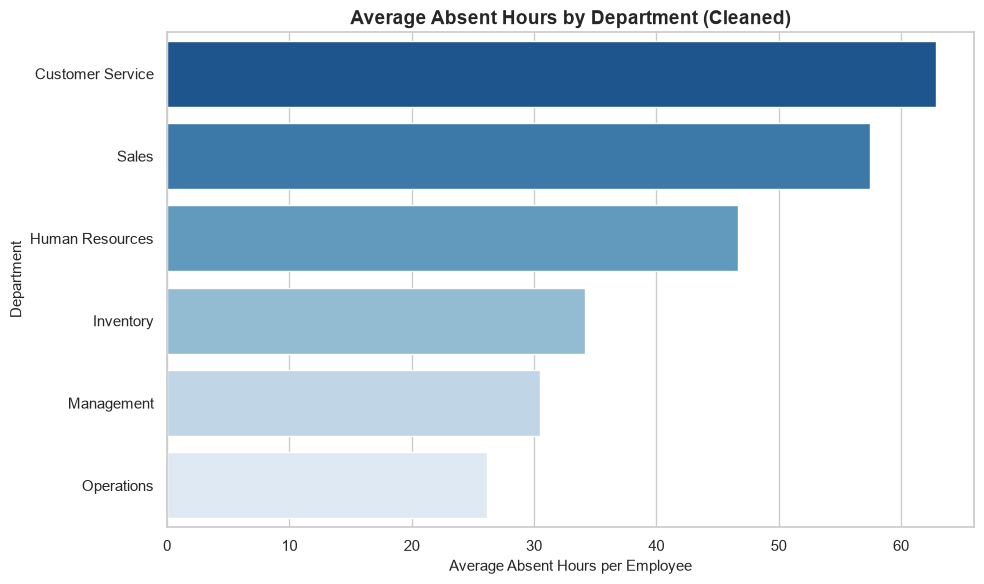

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_theme(style="whitegrid")

# 1. Standardize Department text casing and remove trailing spaces
df["Department"] = df["Department"].astype(str).str.strip().str.title()

# 2. Recalculate average absent hours by cleaned department
dept_absence = (
    df.groupby("Department")["AbsentHours"]
    .mean()
    .reset_index()
    .sort_values(by="AbsentHours", ascending=False)
)

print("--- Updated Average Absent Hours by Department ---")
print(dept_absence)

# 3. Generate Cleaned Department Absenteeism Bar Chart
plt.figure(figsize=(10, 6))

# Using hue='Department' with legend=False satisfies modern Seaborn standards
sns.barplot(
    data=dept_absence,
    x="AbsentHours",
    y="Department",
    hue="Department",
    palette="Blues_r",
    legend=False,
)

plt.title(
    "Average Absent Hours by Department (Cleaned)", fontsize=14, fontweight="bold"
)
plt.xlabel("Average Absent Hours per Employee", fontsize=11)
plt.ylabel("Department", fontsize=11)
plt.tight_layout()

# Save figure for your report deck
plt.savefig("C:/Users/natna/Downloads/WORKFORCE PERFORMANCE/WORK-PERFORMANCE-AND-ABSENTEEISM-ANALYSIS/outputs/figures/cleaned_department_absenteeism.png", dpi=300)
plt.show()